# Loss и графики обучения: как понять, что происходит с моделью

Этот ноутбук объясняет, что такое **функция потерь (loss)**, как читать кривые обучающей и валидационной ошибки и какие выводы можно сделать по их форме. Примеры ориентированы на классификацию животных с ResNet18, но справедливы и для других задач классификации.

После прохождения ноутбука вы сможете отличать нормальное обучение от переобучения, недообучения, слишком большого или слишком маленького learning rate, а также понимать, почему loss и F1 иногда изменяются в разных направлениях.

> Все числовые и графические примеры ниже синтетические: они нужны, чтобы показать характерные формы кривых. Для них не требуется загружать датасет.

## 1. Что такое loss

**Loss** — это число, показывающее, насколько предсказание модели не совпадает с правильным ответом. Оптимизатор изменяет веса модели так, чтобы уменьшать это число.

В многоклассовой классификации модель обычно выдаёт **логиты** — по одному числу на каждый класс. Функция `CrossEntropyLoss`:

1. преобразует логиты в вероятности через softmax;
2. берёт вероятность правильного класса;
3. вычисляет отрицательный логарифм этой вероятности;
4. усредняет результат по объектам батча.

Чем меньше вероятность, которую модель дала правильному классу, тем больше loss. При этом loss зависит не только от правильности итогового класса, но и от **уверенности модели**.

In [1]:
import torch
import torch.nn.functional as F

# Два изображения и три класса: ["олень", "тигр", "кабан"].
logits = torch.tensor([
    [2.0, 1.0, 0.1],   # правильный класс 0 — модель уверена
    [0.2, 1.8, 0.5],   # правильный класс 2, но максимум у класса 1 — ошибка
])
target = torch.tensor([0, 2])
probabilities = torch.softmax(logits, dim=1)
loss = F.cross_entropy(logits, target)

# Тот же расчёт вручную: средний отрицательный логарифм вероятности верного класса.
correct_probabilities = probabilities[torch.arange(len(target)), target]
manual_loss = -torch.log(correct_probabilities).mean()

print("Вероятности классов:")
print(probabilities.detach().numpy().round(3))
print("Вероятности правильных классов:", correct_probabilities.detach().numpy().round(3))
print("CrossEntropyLoss:", round(loss.item(), 4))
print("Расчёт вручную:   ", round(manual_loss.item(), 4))

Вероятности классов:
[[0.659 0.242 0.099]
 [0.137 0.678 0.185]]
Вероятности правильных классов: [0.659 0.185]
CrossEntropyLoss: 1.0527
Расчёт вручную:    1.0527


### Как интерпретировать число

В примере второй объект получает большой вклад в loss: модель не просто ошиблась, но и присвоила правильному классу небольшую вероятность.

**Само по себе значение loss не говорит, хорошая модель или плохая.** Оно зависит от:

- числа классов;
- взвешивания классов;
- способа усреднения (`reduction`);
- размера и состава выборки;
- регуляризации, если она добавляется к функции потерь.

Для 21 класса и равномерных вероятностей ориентиром является `ln(21) ≈ 3.045` — это loss случайного равномерного предсказания **без весов классов**. Но сравнивать значения корректно главным образом **внутри одного эксперимента и на одной выборке**.

Важно различать:

- **loss** — то, что непосредственно оптимизирует модель;
- **F1 macro** — метрику качества итоговых предсказаний, по которой в вашем проекте выбирается лучший чекпоинт.

## 2. Train loss и validation loss

- **Train loss** вычисляется на обучающих батчах. Во время обучения применяются аугментации и, если они есть в модели, Dropout и другие случайные операции.
- **Validation loss** вычисляется после прохождения обучающей эпохи на отложенной выборке без обновления весов. В вашем проекте случайные аугментации на валидации отключены.

На графике по горизонтали обычно отложена эпоха, по вертикали — средний loss за эпоху. Смотреть нужно прежде всего на **тренд**, а не на небольшие колебания между соседними точками.

Минимальный validation loss: эпоха 29


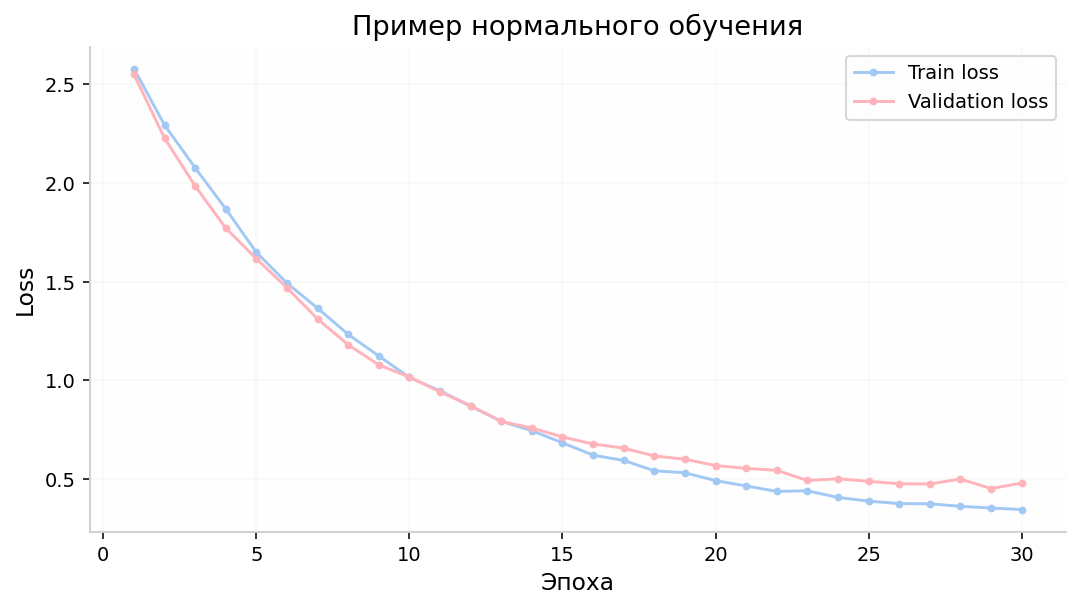

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
epochs = np.arange(1, 31)
train_loss = 2.6 * np.exp(-epochs / 8) + 0.28 + rng.normal(0, 0.012, len(epochs))
val_loss = 2.4 * np.exp(-epochs / 7) + 0.43 + rng.normal(0, 0.018, len(epochs))

plt.figure(figsize=(9, 4.5))
plt.plot(epochs, train_loss, marker='o', ms=3, label='Train loss')
plt.plot(epochs, val_loss, marker='o', ms=3, label='Validation loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.title('Пример нормального обучения')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f'Минимальный validation loss: эпоха {epochs[np.argmin(val_loss)]}')

### Что видно на нормальном графике

Обе кривые снижаются, затем выходят на плато. Небольшой разрыв между train и validation — обычное явление: модель адаптируется именно к обучающим данным.

Нормальный график **не обязан** заканчиваться нулевым loss. Близкий к нулю train loss при заметно более высоком validation loss часто означает запоминание обучающих примеров, а не идеальное качество.

## 3. Типичные формы графиков и их диагностика

Ниже четыре характерных сценария. Обратите внимание не на конкретные числа, а на форму кривых.

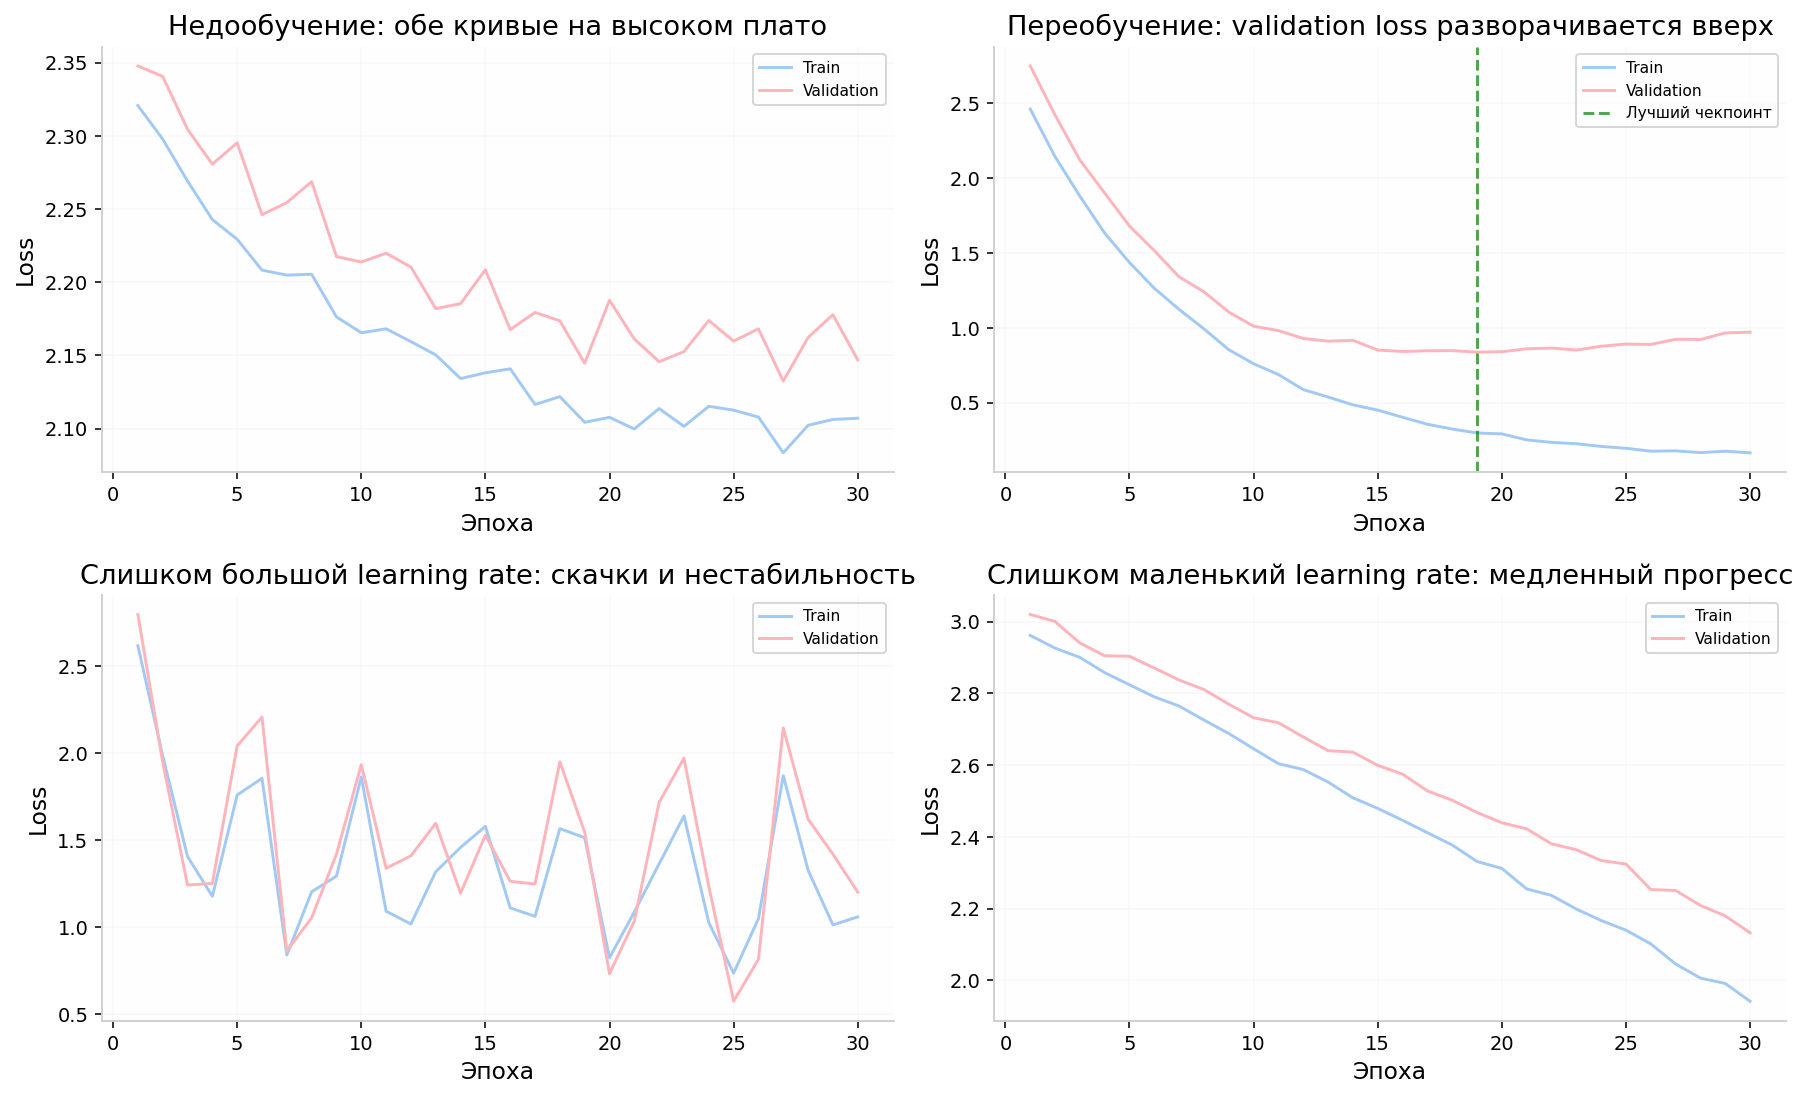

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
epochs = np.arange(1, 31)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# 1. Недообучение: обе ошибки высокие и почти перестали снижаться.
train = 2.35 - 0.25 * (1 - np.exp(-epochs / 8)) + rng.normal(0, 0.01, len(epochs))
val = train + 0.05 + rng.normal(0, 0.015, len(epochs))
axes[0, 0].plot(epochs, train, label='Train')
axes[0, 0].plot(epochs, val, label='Validation')
axes[0, 0].set_title('Недообучение: обе кривые на высоком плато')

# 2. Переобучение: validation loss начинает расти после точки минимума.
train = 2.7 * np.exp(-epochs / 7) + 0.12 + rng.normal(0, 0.01, len(epochs))
val = 2.6 * np.exp(-epochs / 6) + 0.55 + 0.02 * np.maximum(epochs - 10, 0)
val += rng.normal(0, 0.015, len(epochs))
axes[0, 1].plot(epochs, train, label='Train')
axes[0, 1].plot(epochs, val, label='Validation')
axes[0, 1].axvline(np.argmin(val) + 1, color='green', ls='--', alpha=0.7, label='Лучший чекпоинт')
axes[0, 1].set_title('Переобучение: validation loss разворачивается вверх')

# 3. Слишком большой learning rate: нестабильность и скачки.
train = np.clip(1.25 + 1.2 * np.exp(-epochs / 4) + 0.42 * np.sin(epochs * 1.45) + rng.normal(0, 0.16, len(epochs)), 0.15, None)
val = np.clip(train + 0.15 + 0.25 * np.cos(epochs * 1.1) + rng.normal(0, 0.12, len(epochs)), 0.2, None)
axes[1, 0].plot(epochs, train, label='Train')
axes[1, 0].plot(epochs, val, label='Validation')
axes[1, 0].set_title('Слишком большой learning rate: скачки и нестабильность')

# 4. Слишком маленький learning rate: очень медленное снижение.
train = 3.0 - 0.035 * epochs + rng.normal(0, 0.008, len(epochs))
val = 3.05 - 0.030 * epochs + rng.normal(0, 0.012, len(epochs))
axes[1, 1].plot(epochs, train, label='Train')
axes[1, 1].plot(epochs, val, label='Validation')
axes[1, 1].set_title('Слишком маленький learning rate: медленный прогресс')

for ax in axes.flat:
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Loss')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Как читать каждый случай

**1. Недообучение.** Train и validation loss высокие, обе кривые почти не улучшаются. Модель не смогла выучить даже обучающие закономерности.

Что попробовать: обучать дольше, увеличить learning rate, проверить корректность данных и кода, уменьшить чрезмерно сильные аугментации, взять более ёмкую модель.

**2. Переобучение.** Train loss продолжает снижаться, а validation loss после некоторой эпохи растёт. Модель всё лучше подгоняется под train, но становится хуже на новых данных.

Что попробовать: остановиться на лучшем чекпоинте, усилить или правильно подобрать аугментации, добавить weight decay, уменьшить модель или собрать больше данных. Дополнительные эпохи после устойчивого роста validation loss обычно не помогают.

**3. Слишком большой learning rate.** Loss скачет, нестабилен или становится `NaN`. Большие обновления весов мешают оптимизатору попасть в хороший минимум.

Что попробовать: уменьшить learning rate в 3–10 раз, использовать scheduler, warmup или gradient clipping. Однако отдельные редкие скачки могут быть просто следствием сложных батчей.

**4. Слишком маленький learning rate.** Loss стабильно снижается, но очень медленно. Если обе кривые ещё заметно улучшаются к последней эпохе, модель, вероятно, просто не успела дообучиться.

Что попробовать: увеличить число эпох или умеренно повысить learning rate.

## 4. Loss и F1 могут двигаться в разных направлениях

F1 зависит от итоговых предсказанных классов, а cross-entropy — ещё и от вероятностей. Поэтому возможны ситуации:

- модель чаще угадывает класс, но на оставшихся ошибках становится слишком уверенной — **F1 растёт, а loss ухудшается**;
- вероятности становятся лучше откалиброваны, но итоговые классы почти не меняются — **loss снижается, а F1 стоит на месте**;
- средний loss улучшается за счёт частых классов, а редкие классы не улучшаются — **F1 macro при этом может падать**.

Лучшая эпоха по validation loss: 18
Лучшая эпоха по validation F1:   12


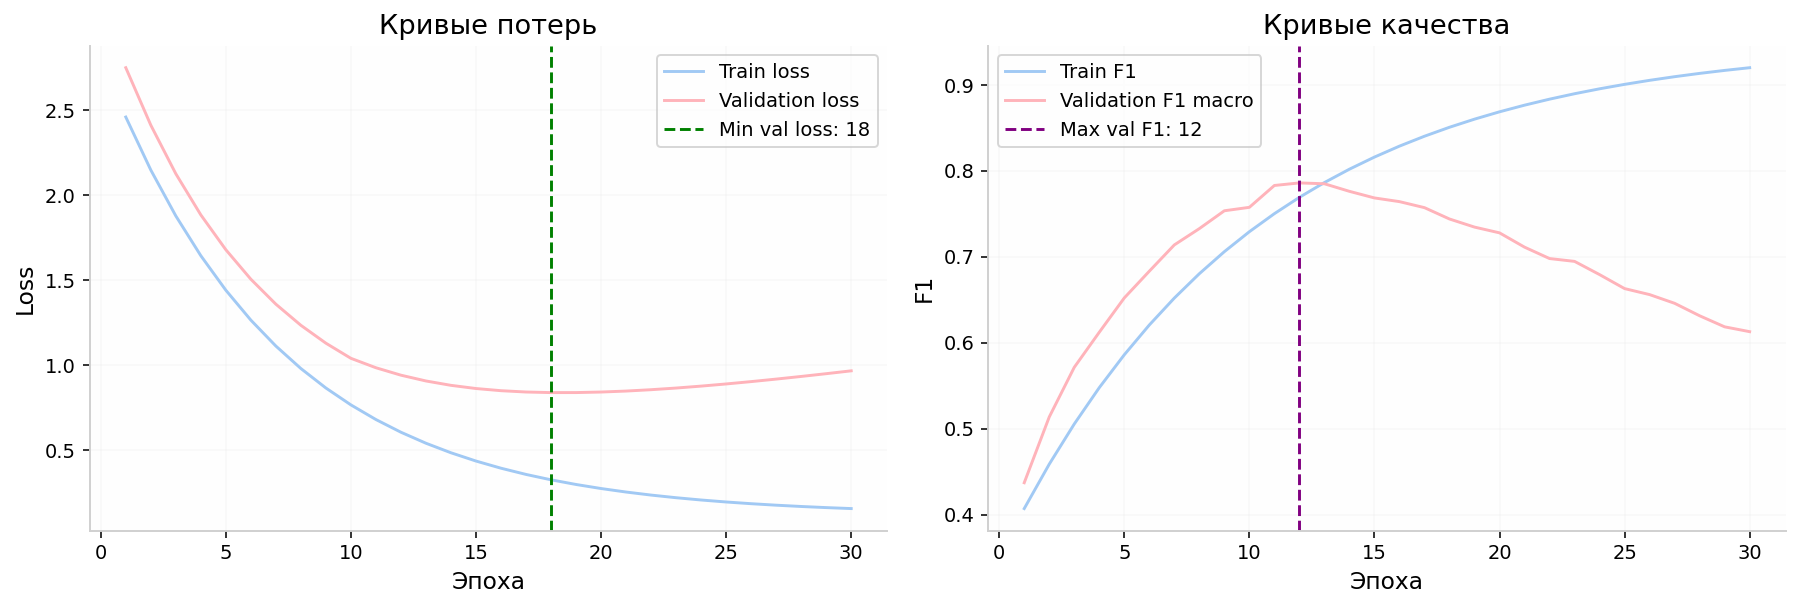

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)
epochs = np.arange(1, 31)
train_loss = 2.7 * np.exp(-epochs / 7) + 0.12
val_loss = 2.6 * np.exp(-epochs / 6) + 0.55 + 0.02 * np.maximum(epochs - 10, 0)
train_f1 = 0.35 + 0.60 * (1 - np.exp(-epochs / 10))
val_f1 = 0.35 + 0.48 * (1 - np.exp(-epochs / 5)) - 0.012 * np.maximum(epochs - 12, 0)
val_f1 += rng.normal(0, 0.004, len(epochs))

best_loss_epoch = int(epochs[np.argmin(val_loss)])
best_f1_epoch = int(epochs[np.argmax(val_f1)])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, train_loss, label='Train loss')
axes[0].plot(epochs, val_loss, label='Validation loss')
axes[0].axvline(best_loss_epoch, color='green', ls='--', label=f'Min val loss: {best_loss_epoch}')
axes[0].set_ylabel('Loss')
axes[0].set_title('Кривые потерь')
axes[0].legend()

axes[1].plot(epochs, train_f1, label='Train F1')
axes[1].plot(epochs, val_f1, label='Validation F1 macro')
axes[1].axvline(best_f1_epoch, color='purple', ls='--', label=f'Max val F1: {best_f1_epoch}')
axes[1].set_ylabel('F1')
axes[1].set_title('Кривые качества')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

print(f'Лучшая эпоха по validation loss: {best_loss_epoch}')
print(f'Лучшая эпоха по validation F1:   {best_f1_epoch}')

### Какую эпоху выбирать

Если цель соревнования — **F1 macro**, разумно сохранять чекпоинт с максимальным валидационным F1, как это сделано в вашем проекте. Минимум validation loss и максимум F1 не обязаны совпадать.

При этом смотреть только на F1 недостаточно: график loss помогает заметить нестабильность, переобучение, проблемы с learning rate и чрезмерную уверенность модели в ошибках.

## 5. Почему validation loss иногда ниже train loss

Это не обязательно утечка данных или ошибка. В вашем проекте есть особенно важная причина: **на обучении применяются аугментации, а на валидации — нет**. Поэтому обучающие изображения могут быть объективно сложнее.

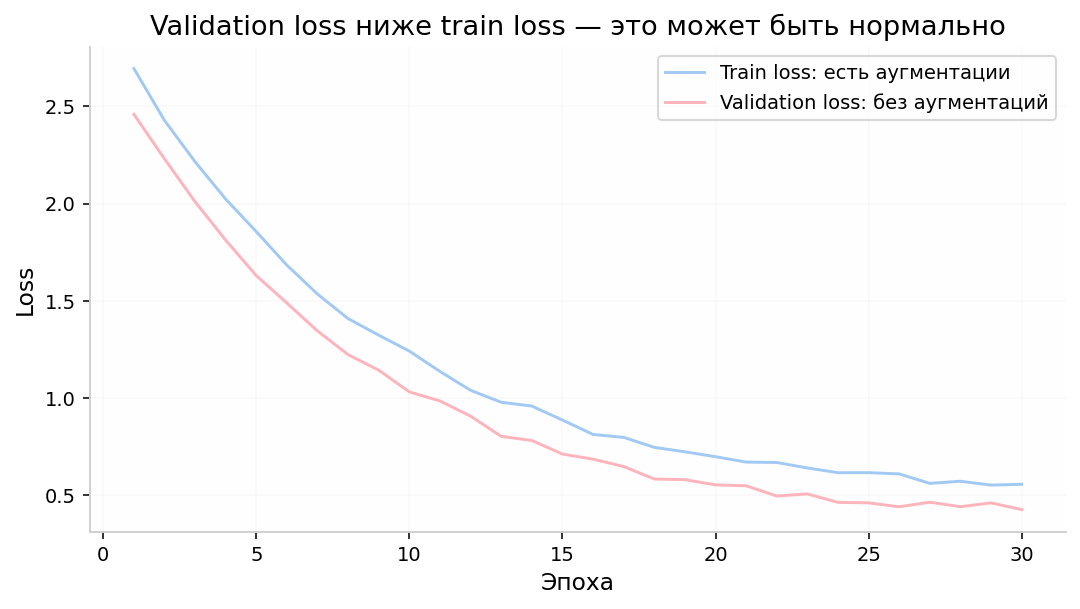

In [5]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(5)
epochs = np.arange(1, 31)
train_loss = 2.5 * np.exp(-epochs / 8) + 0.50 + rng.normal(0, 0.015, len(epochs))
val_loss = 2.4 * np.exp(-epochs / 8) + 0.36 + rng.normal(0, 0.015, len(epochs))

plt.figure(figsize=(9, 4.5))
plt.plot(epochs, train_loss, label='Train loss: есть аугментации')
plt.plot(epochs, val_loss, label='Validation loss: без аугментаций')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.title('Validation loss ниже train loss — это может быть нормально')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

Другие возможные причины:

- Dropout и другие случайные операции активны на train, но отключены на validation;
- train loss усредняется по батчам **во время** эпохи, когда веса постоянно меняются, а validation loss считается уже для итоговых весов эпохи;
- валидационная выборка случайно оказалась проще;
- распределения train и validation различаются — это уже повод проверить разбиение данных.

Опасный сигнал — не само положение кривых друг относительно друга, а **устойчивое ухудшение валидационного качества при продолжающемся улучшении на train**.

## 6. Loss при дисбалансе классов

В вашем проекте одновременно используются:

- `WeightedRandomSampler`, который чаще показывает модели редкие классы;
- `CrossEntropyLoss(weight=class_weights)`, который сильнее штрафует ошибки на редких классах.

Оба приёма меняют вклад классов в обучение. Вместе они иногда дают **двойную компенсацию дисбаланса**: редкие классы и чаще встречаются, и получают больший вес ошибки. Это не обязательно плохо, но может привести к слишком агрессивному предпочтению редких классов и росту ошибок на частых.

Стоит сравнить на одинаковой валидации три варианта:

1. только sampler;
2. только веса в loss;
3. sampler и веса вместе.

**Loss из таких экспериментов нельзя сравнивать напрямую**: разные веса и распределение батчей фактически задают разные функции потерь. Сравнивайте прежде всего F1 macro и качество по отдельным классам на одной и той же валидации.

## 7. Удобный график для вашего проекта

Функция ниже использует списки `train_losses`, `val_losses`, `train_f1_scores` и `val_f1_scores`, которые уже создаются в вашем ноутбуке. Запускать её нужно после цикла обучения.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def plot_training_history(train_losses, val_losses, train_f1_scores, val_f1_scores):
    """Строит loss и F1, отмечая лучшие эпохи по валидации."""
    epochs = np.arange(1, len(train_losses) + 1)
    best_loss_epoch = int(epochs[np.argmin(val_losses)])
    best_f1_epoch = int(epochs[np.argmax(val_f1_scores)])

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    axes[0].plot(epochs, train_losses, marker='o', ms=3, label='Train loss')
    axes[0].plot(epochs, val_losses, marker='o', ms=3, label='Validation loss')
    axes[0].axvline(best_loss_epoch, color='green', ls='--',
                    label=f'Min val loss: эпоха {best_loss_epoch}')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Динамика функции потерь')

    axes[1].plot(epochs, train_f1_scores, marker='o', ms=3, label='Train F1 macro')
    axes[1].plot(epochs, val_f1_scores, marker='o', ms=3, label='Validation F1 macro')
    axes[1].axvline(best_f1_epoch, color='purple', ls='--',
                    label=f'Max val F1: эпоха {best_f1_epoch}')
    axes[1].set_ylabel('F1 macro')
    axes[1].set_title('Динамика качества')

    for ax in axes:
        ax.set_xlabel('Эпоха')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)

    fig.tight_layout()
    plt.show()

    print(f'Последний validation loss: {val_losses[-1]:.4f}')
    print(f'Последний validation F1:   {val_f1_scores[-1]:.4f}')
    print(f'Лучший validation F1:      {max(val_f1_scores):.4f} (эпоха {best_f1_epoch})')


# Вызов после обучения в вашем проекте:
# plot_training_history(train_losses, val_losses, train_f1_scores, val_f1_scores)

## 8. Шаблон early stopping

Ранняя остановка прекращает обучение, если выбранная метрика не улучшается заданное число эпох. Поскольку в вашем проекте цель — F1 macro, ниже остановка и сохранение чекпоинта выполняются именно по ней.

Функцию нужно определить до цикла обучения, а вызов поместить после вычисления `val_f1` в конце каждой эпохи.

In [ ]:
import torch


best_val_f1 = float('-inf')
epochs_without_improvement = 0


def update_early_stopping(val_f1, epoch, model, best_model_path='best_model.pth', patience=5):
    """Сохраняет лучшую модель и возвращает True, когда обучение пора остановить."""
    global best_val_f1, epochs_without_improvement

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        torch.save(model.state_dict(), best_model_path)
        print(f'Эпоха {epoch + 1}: сохранён новый лучший чекпоинт, F1={val_f1:.4f}')
    else:
        epochs_without_improvement += 1
        print(f'Эпоха {epoch + 1}: без улучшения {epochs_without_improvement}/{patience}')

    return epochs_without_improvement >= patience


# Пример использования в конце эпохи вашего цикла:
# if update_early_stopping(val_f1, epoch, model, patience=5):
#     print('Ранняя остановка обучения')
#     break

## 9. Краткая таблица диагностики

| Наблюдение | Вероятная причина | Первое действие |
|---|---|---|
| Train и val loss высокие, обе кривые на плато | Недообучение | Проверить данные, обучать дольше или увеличить learning rate |
| Train loss падает, val loss устойчиво растёт | Переобучение | Взять лучший чекпоинт, скорректировать регуляризацию и аугментации |
| Loss сильно скачет или становится `NaN` | Слишком большой learning rate, численная нестабильность | Уменьшить learning rate, проверить данные |
| Обе кривые почти не меняются | Слишком маленький learning rate или ошибка в обновлении весов | Проверить `optimizer.step()`, градиенты и learning rate |
| Val loss ниже train loss | Аугментации/Dropout на train, различие выборок | Проверить тренд и разбиение; само по себе это не ошибка |
| Loss растёт, F1 улучшается | Меняется уверенность предсказаний, а не только их правильность | Выбирать чекпоинт по целевой метрике, но проверить переобучение |
| Train F1 растёт, val F1 падает | Переобучение | Остановиться на максимуме val F1 |
| Val loss и F1 сильно колеблются | Маленькая или сложная валидация, большой learning rate | Проверить размер валидации, seed и стабильность обучения |

## 10. Практический чек-лист

После каждого эксперимента полезно ответить на вопросы:

1. Снижаются ли train и validation loss в начале обучения?
2. Продолжает ли улучшаться валидация к последней эпохе? Если да, модель можно обучать дольше.
3. Есть ли устойчивый рост validation loss или снижение validation F1 при улучшении train? Если да, это переобучение.
4. Совпадают ли лучшие эпохи по loss и F1? Если нет, для соревнования выбирайте чекпоинт по целевой метрике.
5. Нет ли резких скачков, `NaN` или почти полного отсутствия изменений? Это повод проверить learning rate и корректность обучающего цикла.
6. Одинаковы ли данные, веса классов и способ расчёта loss между экспериментами? Если нет, абсолютные значения loss напрямую не сравнивают.
7. Как изменилась F1 по редким классам? Средний loss может скрывать их ухудшение.

**Главное правило:** читайте train loss, validation loss и целевую метрику вместе. Одна кривая редко даёт полную картину качества модели.